# Water vapour

> Estimate the water-vapour line pattern from the differences between replicate scans, score every Fukushima and OSSL spectrum for it, and test whether it explains the transfer failure

In [ ]:
#| default_exp vapour

In [ ]:
#| export
import numpy as np
from scipy.signal import savgol_filter

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from fastcore.test import *
from soilspecdata.all import load_ossl
from soilspecdata.readers import read_spa
from ossl_fuku_transfer.data import *
from ossl_fuku_transfer.transfer import *
from ossl_fuku_transfer.inside import tracked_model

/Users/franckalbinet/pro/dev/soilspec/ossl-fuku-transfer/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Water vapour in the beam of an FTIR spectrometer adds many narrow lines, in the H–O–H bending region (about 1300–2000 cm⁻¹) and the O–H stretching region (about 3500–3950 cm⁻¹). No soil component gives lines that narrow. A spectrum is the sample scan against a background scan, so the lines can point up, if the sample scan had more vapour, or down, if the background had more. `01_pca` found more narrow structure in the Fukushima spectra than in OSSL between 1300 and 2000 cm⁻¹.

The replicate scans of a sample measure the same soil. Their differences hold the measurement differences, such as vapour and noise, and no soil differences. They show the vapour pattern most clearly.

The module part uses small random arrays, so it runs without the data. The sections from *Native grid* onwards read OSSL and the Fukushima data, and are marked `#| fukudata`.

## Functions

`highpass` keeps the narrow structure of each spectrum: the spectrum minus a Savitzky-Golay smooth with a window of `window` points. On the 2 cm⁻¹ grid, 11 points is 22 cm⁻¹, narrower than most soil bands and wider than vapour lines. `band_mask` marks the wavenumbers in `bands`:

In [ ]:
#| export
vapour_bands = [(1300, 2000), (3500, 3950)] # Wavenumber ranges of the water-vapour lines, in cm⁻¹

def highpass(
    X, # Spectra, one per row
    window=11, # Window of the Savitzky-Golay smooth, in points, odd
    polyorder=2, # Degree of the smoothing polynomial
)->np.ndarray:
    "`X` minus its Savitzky-Golay smooth"
    X = np.asarray(X, dtype=float)
    return X - savgol_filter(X, window, polyorder, axis=-1)

def band_mask(
    wns, # Wavenumbers
    bands=vapour_bands, # (low, high) ranges, in cm⁻¹
)->np.ndarray: # True for the wavenumbers in any of `bands`
    "Mask of the wavenumbers within `bands`"
    wns = np.asarray(wns)
    return np.any([(wns >= lo) & (wns <= hi) for lo, hi in bands], axis=0)

`replicate_deviations` subtracts from each replicate the mean of its sample's replicates, for samples with at least two. `vapour_pattern` returns the first principal component of high-passed spectra within `mask`, as a unit vector that is zero outside `mask`, with its sign set so that its largest entry is positive. It also returns that component's share of the variance within `mask`. `vapour_score` projects the high-passed spectra on a pattern:

In [ ]:
#| export
def replicate_deviations(
    X, # Replicate spectra, one per row
    sample_ids, # Sample ID of each row
)->tuple: # (Deviations from the sample mean, their sample IDs), for samples with two replicates or more
    "Each replicate minus the mean of its sample's replicates"
    sample_ids = np.asarray(sample_ids)
    rows, sids = [], []
    for i in dict.fromkeys(sample_ids):
        R = X[sample_ids == i]
        if len(R) < 2: continue
        rows.append(R - R.mean(0))
        sids += [i] * len(R)
    return np.vstack(rows), np.array(sids)

def vapour_pattern(
    H, # High-passed spectra or deviations, one per row
    mask, # True for the wavenumbers to use, such as from `band_mask`
)->tuple: # (Unit pattern over all wavenumbers, share of variance within `mask`)
    "First principal component of `H` within `mask`"
    Hm = H[:, mask] - H[:, mask].mean(0)
    _, s, Vt = np.linalg.svd(Hm, full_matrices=False)
    v = np.zeros(H.shape[1])
    v[mask] = Vt[0] * np.sign(Vt[0][np.argmax(np.abs(Vt[0]))])
    return v, float(s[0]**2 / (s**2).sum())

def vapour_score(
    X, # Spectra, one per row, on the wavenumbers of `v`
    v, # Pattern from `vapour_pattern`
    window=11, # Passed to `highpass`
)->np.ndarray: # One score per spectrum
    "Projection of the high-passed spectra on the pattern `v`"
    return highpass(X, window) @ v

A test with synthetic spectra: smooth curves for the soils, plus a random amount of a pattern of narrow lines, which differs between the replicates of a sample. The functions recover the pattern and the amounts:

In [ ]:
rng = np.random.default_rng(0)
wns_syn = np.arange(650, 3999, 2.)
mask = band_mask(wns_syn)
lines = np.zeros(len(wns_syn))
lines[mask] = np.sin(wns_syn[mask] * 1.7) * (rng.random(mask.sum()) > 0.6)
soil = np.array([np.polyval(rng.normal(size=4), (wns_syn - 2300) / 1700) for _ in range(30)])
amt = rng.normal(size=(30, 4))
X_rep = np.repeat(soil, 4, axis=0) + 0.02 * amt.reshape(-1, 1) * lines + 0.001 * rng.normal(size=(120, len(wns_syn)))
ids_rep = np.repeat(np.arange(30), 4)
D, _ = replicate_deviations(X_rep, ids_rep)
v, share = vapour_pattern(highpass(D), mask)
test_eq(abs(np.corrcoef(v[mask], highpass(lines[None])[0][mask])[0, 1]) > 0.95, True)
test_eq(abs(np.corrcoef(vapour_score(X_rep, v), amt.ravel())[0, 1]) > 0.95, True)
round(share, 3)

0.99

## Native grid

The Fukushima spectra are interpolated onto the shared 2 cm⁻¹ grid. The point spacing of the `.spa` files shows whether that grid keeps their narrow structure:

In [ ]:
#| fukudata
files = spa_files()
ids = sample_ids()
grids = {}
for i in ids[::50]:
    x, _, _ = read_spa(files[i][0])
    grids[i] = (len(x), round(x[0], 2), round(x[-1], 2), round(float(np.diff(x).mean()), 3))
pd.DataFrame(grids, index=['points', 'from', 'to', 'spacing']).T.drop_duplicates()

,points,from,to,spacing
20,1764.0,599.75,3999.64,1.928
1246,1738.0,649.89,3999.64,1.928


## Vapour pattern

Every replicate of the current selection on the shared grid. The pattern from the replicate deviations (approach 3), and the pattern from the averaged sample spectra (approach 2), with the share of variance each first component holds within the vapour bands:

In [ ]:
#| fukudata
reps = load_replicates()
fuku = load_fuku()
mask = band_mask(shared_wns)
D, d_ids = replicate_deviations(reps.spectra, reps.sample_ids)
v_rep, share_rep = vapour_pattern(highpass(D), mask)
v_avg, share_avg = vapour_pattern(highpass(fuku.spectra), mask)
{'replicates': len(reps.sample_ids), 'samples with 2 or more': len(np.unique(d_ids)), 'share, replicate deviations': round(share_rep, 3),
 'share, sample spectra': round(share_avg, 3), 'r between the two patterns': round(float(np.corrcoef(v_rep[mask], v_avg[mask])[0, 1]), 3)}

{'replicates': 5546,
 'samples with 2 or more': 1388,
 'share, replicate deviations': 0.261,
 'share, sample spectra': 0.604,
 'r between the two patterns': 0.988}

Both patterns, in each vapour band:

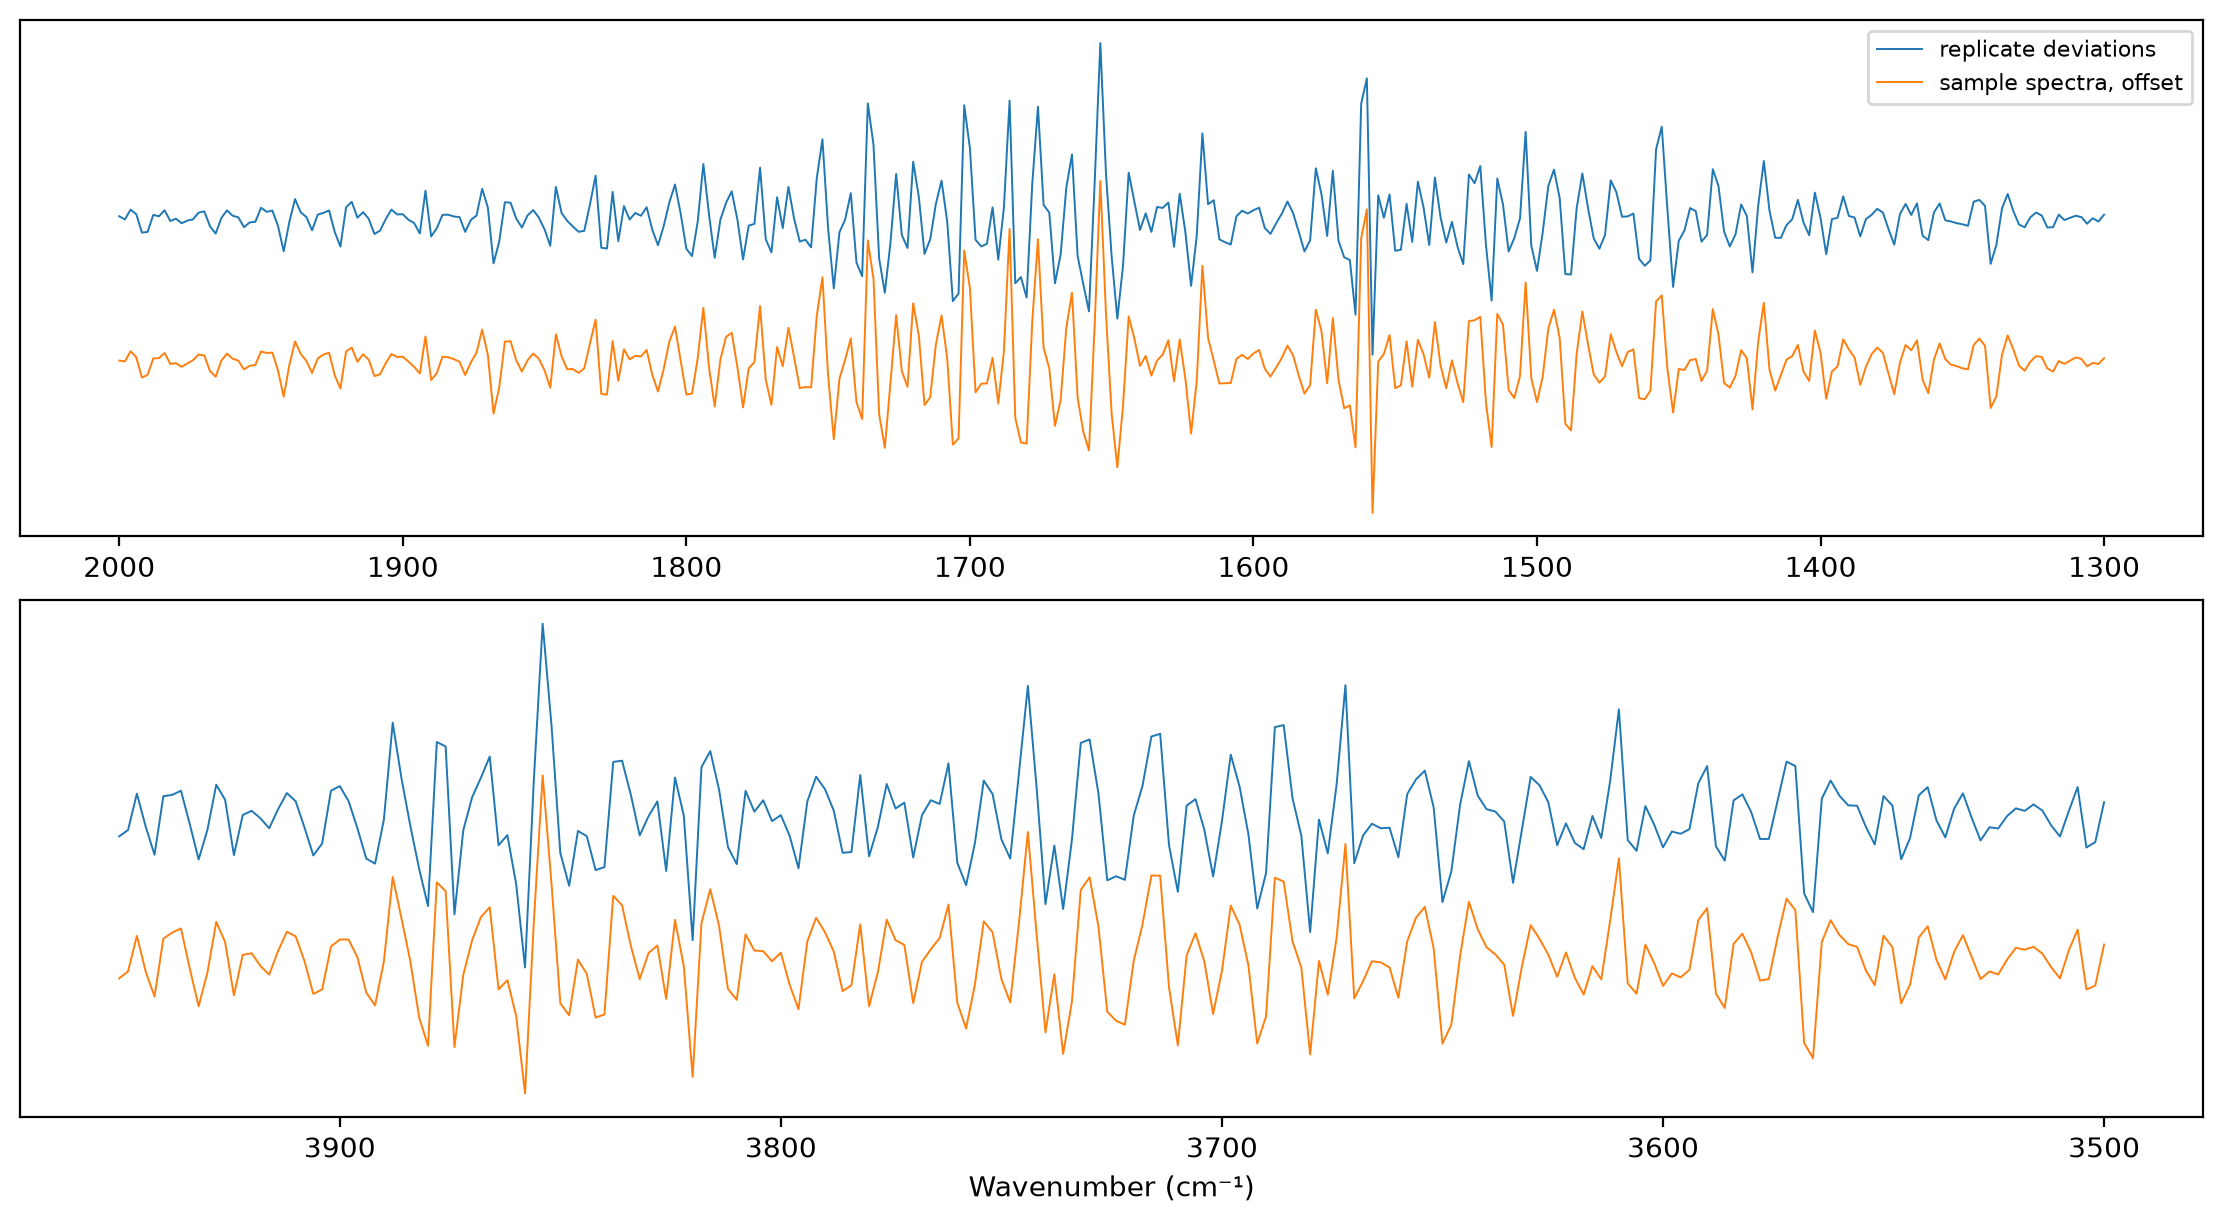

In [ ]:
#| fukudata
fig, axs = plt.subplots(2, 1, figsize=(11, 6), layout='constrained')
for ax, (lo, hi) in zip(axs, vapour_bands):
    m = (shared_wns >= lo) & (shared_wns <= hi)
    ax.plot(shared_wns[m], v_rep[m], lw=0.7, label='replicate deviations')
    ax.plot(shared_wns[m], v_avg[m] - 0.15, lw=0.7, label='sample spectra, offset')
    ax.invert_xaxis(); ax.set_yticks([])
axs[0].legend(fontsize=8); axs[1].set_xlabel('Wavenumber (cm⁻¹)');

## Scores

Each Fukushima sample's score is the projection of its averaged spectrum on the replicate pattern. Positive scores mean the vapour lines point up, so the sample scans held more vapour than the background, and negative scores the reverse. The spread of the scores of a sample's replicates shows how much vapour varied between scans. OSSL spectra, 10,000 drawn at random, get the same score. The quantiles of the scores:

In [ ]:
#| fukudata
s_f = pd.Series(vapour_score(fuku.spectra, v_rep), index=fuku.sample_ids)
s_rep = pd.Series(vapour_score(reps.spectra, v_rep)).groupby(reps.sample_ids).std()
om = load_ossl().mir(wmin=shared_wns[0], wmax=shared_wns[-1])
sub = np.random.default_rng(0).choice(len(om.spectra), 10000, replace=False)
s_o = vapour_score(om.spectra[sub], v_rep)
qs = [0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
pd.DataFrame({'Fukushima': s_f.quantile(qs).to_numpy(), 'OSSL': np.quantile(s_o, qs), 'Fukushima, |score|': s_f.abs().quantile(qs).to_numpy(),
              'OSSL, |score|': np.quantile(np.abs(s_o), qs), 'Fukushima, spread of replicates': s_rep.quantile(qs).to_numpy()}, index=qs).round(4)

,Fukushima,OSSL,"Fukushima, |score|","OSSL, |score|","Fukushima, spread of replicates"
0.01,-0.0163,-0.0060,0.0000,0.0000,0.0000
0.05,-0.0131,-0.0046,0.0002,0.0001,0.0001
0.25,-0.0063,-0.0026,0.0013,0.0006,0.0001
0.50,-0.0032,-0.0014,0.0033,0.0015,0.0002
0.75,-0.0012,-0.0003,0.0064,0.0027,0.0004
0.95,0.0003,0.0008,0.0131,0.0048,0.0010
0.99,0.0042,0.0047,0.0163,0.0074,0.0023


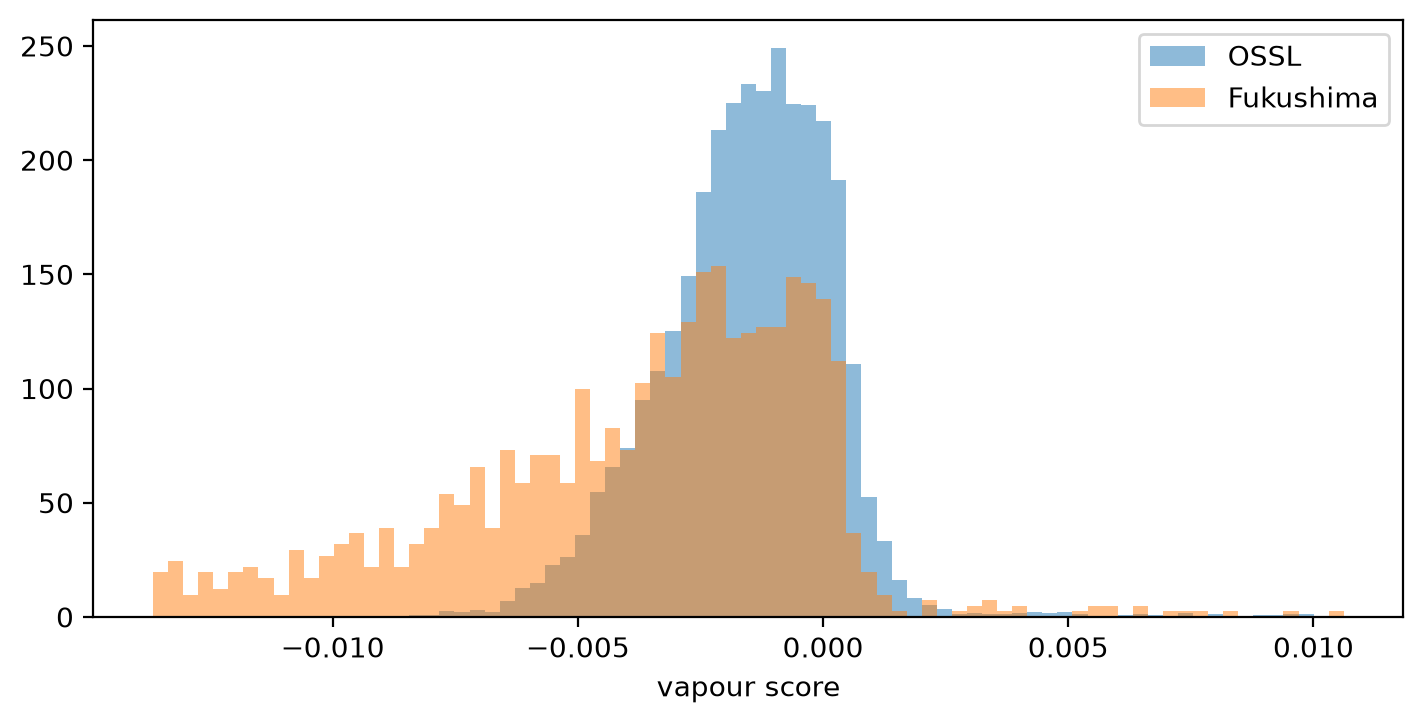

In [ ]:
#| fukudata
fig, ax = plt.subplots(figsize=(7, 3.5), layout='constrained')
bins = np.linspace(np.quantile(np.r_[s_f, s_o], 0.005), np.quantile(np.r_[s_f, s_o], 0.995), 80)
ax.hist(s_o, bins, density=True, alpha=0.5, label='OSSL')
ax.hist(s_f, bins, density=True, alpha=0.5, label='Fukushima')
ax.set_xlabel('vapour score'); ax.legend();

The scores by measurement batch and by year:

In [ ]:
#| fukudata
meta = pd.DataFrame({'score': s_f, 'batch': sample_batches(fuku.sample_ids), 'year': fuku.source['year'].reindex(fuku.sample_ids).to_numpy()})
meta.groupby('batch')['score'].describe()[['count', 'mean', 'std', 'min', 'max']].round(4), meta.groupby('year')['score'].describe()[['count', 'mean', 'std']].round(4)

(         count    mean     std     min     max
 batch                                         
 batch 1  535.0 -0.0056  0.0057 -0.0178  0.0116
 batch 2  854.0 -0.0032  0.0026 -0.0114  0.0011,
         count    mean     std
 year                         
 2013.0   86.0 -0.0037  0.0036
 2014.0  238.0 -0.0064  0.0057
 2015.0  140.0 -0.0045  0.0045
 2016.0  194.0 -0.0032  0.0031
 2017.0  184.0 -0.0049  0.0041
 2018.0  213.0 -0.0036  0.0046
 2019.0  185.0 -0.0032  0.0025
 2020.0  149.0 -0.0030  0.0022)

## Vapour and the transfer failure

Kex errors against the vapour score: the zero-shot error of the pretrained OSSL model on all samples, and the residuals of the fully fine-tuned and Fukushima-only models of `06_dynamics` on the test samples. The Spearman correlation of each error, and of its absolute value, with the score and with its absolute value:

In [ ]:
#| fukudata
fuku.source = fuku.source.assign(target=fuku.source['soil_ex_K2O'] / mg_k2o_per_cmolc)
Xf, yf, idf = fuku.xy('target')
yf = np.log1p(yf.ravel())
Xf_d = preprocessings()['snv_d1'].fit_transform(Xf)
is_test = np.isin(idf, cs137_split()[1])
sc = s_f.reindex(idf).to_numpy()
errs = {'zero-shot, all': (predict(load_pretrained('ossl_kex_snv_d1'), Xf_d) - yf, np.ones(len(yf), bool)),
        'fully fine-tuned, test': (predict(tracked_model('dyn_fuku_kex_ft'), Xf_d) - yf, is_test),
        'Fukushima only, test': (predict(tracked_model('dyn_fuku_kex_scratch'), Xf_d) - yf, is_test)}
pd.DataFrame({k: {'error vs score': spearmanr(e[m], sc[m])[0], '|error| vs |score|': spearmanr(np.abs(e[m]), np.abs(sc[m]))[0],
                  'error vs |score|': spearmanr(e[m], np.abs(sc[m]))[0]} for k, (e, m) in errs.items()}).T.round(3)

,error vs score,|error| vs |score|,error vs |score|
"zero-shot, all",-0.078,0.085,0.068
"fully fine-tuned, test",-0.045,0.064,0.012
"Fukushima only, test",-0.034,0.025,-0.007


Zero-shot scores of the pretrained OSSL model on the quarters of the samples with the smallest to the largest absolute vapour score:

In [ ]:
#| fukudata
pz = errs['zero-shot, all'][0] + yf
qt = pd.qcut(np.abs(sc), 4, labels=['least vapour', '2nd', '3rd', 'most vapour'])
pd.DataFrame({q: {'n': int((qt == q).sum()), 'median |score|': float(np.median(np.abs(sc[qt == q]))), **scores(yf[qt == q], pz[qt == q])} for q in qt.categories}).T.round(3)

,n,median |score|,R²,r,RMSE,bias
least vapour,347.0,0.001,-0.596,0.190,0.539,0.254
2nd,347.0,0.002,-0.947,0.128,0.607,0.321
3rd,347.0,0.005,-0.602,0.224,0.547,0.285
most vapour,347.0,0.009,-0.921,0.082,0.634,0.340


## Findings

The Fukushima spectra contain a clear water-vapour pattern. The `.spa` files have a point spacing of 1.93 cm⁻¹, so the 2 cm⁻¹ grid keeps their narrow structure. The pattern estimated from replicate deviations and the one estimated from the averaged sample spectra correlate at r 0.99. In the vapour bands, the first component holds 26% of the narrow-structure variance of the replicate deviations, where noise holds much of the rest, and 60% of that of the sample spectra.

The Fukushima vapour lines are about twice as strong as OSSL's, and mostly point down. The median absolute score is 0.0033 for Fukushima and 0.0015 for OSSL, and the 95th percentiles are 0.013 and 0.005. 95% of the Fukushima scores are below 0.0003, so their background scans almost always held more vapour than their sample scans. The scores of a sample's replicates spread much less than the scores vary between samples (median spread 0.0002), so the vapour level was set per session rather than per scan. Batch 1 has more vapour than batch 2 (mean score −0.0056 against −0.0032). The year makes less difference.

Vapour doesn't explain the transfer failure. Its Spearman correlation with the Kex errors is at most 0.09 in absolute value: for the zero-shot error of the OSSL model, and for the residuals of the fully fine-tuned and Fukushima-only models. The OSSL model fails zero-shot on the quarter of the samples with the least vapour too (correlation 0.19, R² −0.60). On the quarter with the most vapour, the correlation is 0.08. The four quarters show no steady trend.

The score measures the narrow vapour lines only. Water held by the soil gives broad bands, near 3400 and 1630 cm⁻¹, which `highpass` removes. This notebook doesn't test that.

In [ ]:
#| hide
import nbdev; nbdev.nbdev_export()